# UCS420 Lab Assignment 7 — NLP Text Preprocessing

---


Enter your roll number and name, then run all cells.

In [5]:
ROLL_NO = 1024160050          # <-- your full roll number
NAME = "BHAGYA VARDHAN"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [9]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [10]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [11]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160050   Name: BHAGYA VARDHAN   Fingerprint: 86CAD48A   Tickets: 12

Ticket_ID                                                                                 Ticket_Text
      T01                                    The VPN is showing an error. I have tried several times!
      T02                                                       It's not the laptop; it's the server.
      T03                    I keep getting logged out of the Python since yesterday. This is urgent.
      T04                                                        Email me at helpdesk@university.edu.
      T05 Student portal has stopped syncing after resetting my password. I have tried several times!
      T06                                               VPN is not working on my laptop. Please help.
      T07                                       Matlab has stopped syncing on my laptop. Please help.
      T08                I couldn't connect to the Wi-Fi before the assignment deadline. Please he

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [12]:
# Your code
import pandas as pd
results = []

for index, row in df.iterrows():
    analysis = process_ticket(row['Ticket_Text'])
    unique_toks = set(analysis['tokens'])

    results.append({
        'Ticket_ID': row['Ticket_ID'],
        'Sentences': len(analysis['sentences']),
        'Tokens': len(analysis['tokens']),
        'Punctuation': len(analysis['punct']),
        'Stopwords': len(analysis['stops']),
        'Unique Tokens': len(unique_toks),
        'Final Tokens': len(analysis['final'])
    })

summary_df = pd.DataFrame(results)

total_row = {
    'Ticket_ID': 'TOTAL',
    'Sentences': summary_df['Sentences'].sum(),
    'Tokens': summary_df['Tokens'].sum(),
    'Punctuation': summary_df['Punctuation'].sum(),
    'Stopwords': summary_df['Stopwords'].sum(),
    'Unique Tokens': summary_df['Unique Tokens'].sum(),
    'Final Tokens': summary_df['Final Tokens'].sum()
}

summary_df = pd.concat([summary_df, pd.DataFrame([total_row])], ignore_index=True)

display(summary_df)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,13,2,5,13,6
1,T02,1,11,2,5,8,4
2,T03,2,15,2,6,14,7
3,T04,1,7,2,2,7,3
4,T05,2,16,2,5,16,9
5,T06,2,11,2,4,10,5
6,T07,2,11,2,3,10,6
7,T08,2,15,2,5,13,8
8,T09,2,12,2,4,12,6
9,T10,2,10,4,3,8,3


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The tokens in this dataset which are not real words include 's which might refer to words like bhagya's etc, and also words like n't which might refer to a negative word like can't ... Contractions ('s, n't): These are produced by NLTK's word_tokenize. Since they do not consist entirely of punctuation and are not found in the standard NLTK English stopwords list, they bypass both filters and end up in the final tokens list.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [13]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

pattern_long_words = r'\b[a-zA-Z]{6,}\b'

pattern_numbers = r'\b\d+(?:\.\d+)+\b|\b\d+\b'

pattern_capitalized = r'\b[A-Z][a-zA-Z]*\b'

pattern_vowels = r'\b[aeiouAEIOU][a-zA-Z]*\b'

pattern_email = r'\b[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b'

pattern_url = r'https?://\S+|www\.\S+'

pattern_phone = r'\+?\d{1,4}[-\s]?\d{2,5}[-\s]?\d{3,5}[-\s]?\d{3,5}|\b\d{4}-\d{3}-\d{4}\b'

def run_extraction_and_sub(lines, title):
    print(f"=== Analysis for {title} ===")
    for idx, text in enumerate(lines):
        print(f"\nLine {idx+1}: {text}")
        print("  Words > 5 letters:", re.findall(pattern_long_words, text))
        print("  Numbers (decimals/versions whole):", re.findall(pattern_numbers, text))
        print("  Capitalized words:", re.findall(pattern_capitalized, text))
        print("  Words starting with vowel:", re.findall(pattern_vowels, text))

        temp_text = re.sub(pattern_email, "<EMAIL>", text)
        temp_text = re.sub(pattern_url, "<URL>", temp_text)
        substituted_text = re.sub(pattern_phone, "<PHONE>", temp_text)
        print("  Substituted text:", substituted_text)

run_extraction_and_sub(TEST_LINES, "TEST_LINES")

run_extraction_and_sub(df['Ticket_Text'].tolist(), "Raw Tickets")

=== Analysis for TEST_LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  Words > 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
  Numbers (decimals/versions whole): []
  Capitalized words: ['Mail']
  Words starting with vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
  Substituted text: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  Words > 5 letters: ['Version']
  Numbers (decimals/versions whole): ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
  Capitalized words: ['Call', 'Version', 'Rs']
  Words starting with vowel: ['or', 'is']
  Substituted text: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  Wor

### **Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Out of all the capitalized tokens extracted, the words **"The", "It", "Email", "Student", "Please", "Is", and "Only"** (spanning a total of **13 occurrences**) are capitalized solely because they start a sentence.

Other capitalized words such as **"VPN"**, **"Python"**, **"Matlab"**, **"PCs"** (which are proper nouns, acronyms, or abbreviations) and **"I"** (the personal pronoun) are always capitalized regardless of their position in a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [14]:
# Your code
from nltk.tokenize import RegexpTokenizer
from nltk.tokenize import word_tokenize

pattern = r'''(?x)
    https?://\S+|www\.\S+
    | [a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b
    | \+?\d{1,4}[-\s]?\d{2,5}[-\s]?\d{3,5}[-\s]?\d{3,5}\b | \b\d{4}-\d{3}-\d{4}\b
    | \b\d+(?:\.\d+)+\b
    | \b[a-zA-Z]+(?:-[a-zA-Z]+)+\b
    | \b[a-zA-Z]+'[a-zA-Z]+\b
    | \b[a-zA-Z0-9]+\b
    | \S
'''

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

def compare_tokenizers(lines, title):
    print(f"=== Comparison for {title} ===")
    for idx, text in enumerate(lines):
        wt = word_tokenize(text)
        mt = my_tokenize(text)
        differs = (wt != mt)
        print(f"\nLine {idx+1}: {text[:60]}...")
        print(f"  Different? {differs}")
        print(f"  word_tokenize ({len(wt)}): {wt}")
        print(f"  my_tokenize   ({len(mt)}): {mt}")

compare_tokenizers(TEST_LINES, "TEST_LINES")

compare_tokenizers(df['Ticket_Text'].tolist(), "Raw Tickets")

=== Comparison for TEST_LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit ...
  Different? True
  word_tokenize (16): ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  my_tokenize   (9): ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Vers...
  Different? True
  word_tokenize (20): ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  my_tokenize   (20): ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']

Line 3: The state-of-the-art lab isn't open; log-in at 5.3

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* Out of the 12 raw tickets, **4 tickets** (T02, T04, T08, and T10) are tokenized differently by `my_tokenize` and `word_tokenize`. This difference occurs because `my_tokenize` keeps contractions (like `It's` and `couldn't`), emails, and URLs together as single tokens, whereas `word_tokenize` splits them.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [15]:
# Your code
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

unique_final_tokens = set()
for text in df['Ticket_Text']:
    analysis = process_ticket(text)
    unique_final_tokens.update(analysis['final'])

unique_final_tokens = sorted(list(unique_final_tokens))

porter = PorterStemmer()
lancaster = LancasterStemmer()

regexp_stemmer = RegexpStemmer('ing$|ed$|s$', min=4)

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

pos_tags = nltk.pos_tag(unique_final_tokens)
word_pos_map = {word: tag for word, tag in pos_tags}

comparison_data = []

for word in unique_final_tokens:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)

    nltk_tag = word_pos_map.get(word, 'N')
    wn_tag = get_wordnet_pos(nltk_tag)
    lemmatized = lemmatizer.lemmatize(word, pos=wn_tag)

    if not (p_stem == l_stem == r_stem == lemmatized):
        comparison_data.append({
            'Original Word': word,
            'POS Tag': nltk_tag,
            'Porter': p_stem,
            'Lancaster': l_stem,
            'RegexpStemmer': r_stem,
            'Lemmatizer': lemmatized
        })

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

,Original Word,POS Tag,Porter,Lancaster,RegexpStemmer,Lemmatizer
0,another,DT,anoth,anoth,another,another
1,assignment,NN,assign,assign,assignment,assignment
2,deadline,VB,deadlin,deadlin,deadline,deadline
3,error,NN,error,er,error,error
4,getting,VBG,get,get,gett,get
5,logged,VBD,log,log,logg,log
6,occurs,VBD,occur,occ,occur,occur
7,pcs,NNS,pc,pcs,pcs,pc
8,please,VBP,pleas,pleas,please,please
9,portal,JJ,portal,port,portal,portal


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

* **Over-stemming Example:**
  * **`another`** is stemmed to **`anoth`** by both `Porter` and `Lancaster`. This is over-stemming because it chops off the end of a word that is already in its base/root form, creating a non-word stem.
  * **`urgent`** is stemmed to **`urg`** by `Lancaster`, which conflates it or reduces it too aggressively.

* **Under-stemming Example:**
  * **`deadline`** is stemmed to **`deadlin`** by `Porter` and `Lancaster`, but is left as **`deadline`** by `RegexpStemmer` (which didn't match its simple ending rules). Similarly, words like **`getting`** and **`showing`** are correctly reduced to **`get`** or **`show`** by some stemmers but might be missed or kept too long depending on the suffix dictionary, representing under-stemming.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== Corpus Statistics (S1 to S4) ===


,Subset,Total Tokens,Unique Tokens (Vocab),TTR
0,S1 (All),144,81,0.562500
1,S2 (No Punct),119,75,0.630252
2,S3 (Final),68,51,0.750000
3,S4 (Stemmed Final),68,50,0.735294



=== Top 10 Words in S1 ===
  .: 16
  the: 9
  is: 5
  i: 5
  !: 5
  tried: 3
  laptop: 3
  my: 3
  please: 3
  help: 3

=== Top 10 Words in S3 ===
  tried: 3
  laptop: 3
  please: 3
  help: 3
  vpn: 2
  showing: 2
  error: 2
  several: 2
  times: 2
  's: 2

=== Top 5 Bigrams in S1 ===
  . i: 4
  . please: 3
  please help: 3
  help .: 3
  vpn is: 2

=== Top 5 Bigrams in S3 ===
  please help: 3
  showing error: 2
  tried several: 2
  several times: 2
  stopped syncing: 2


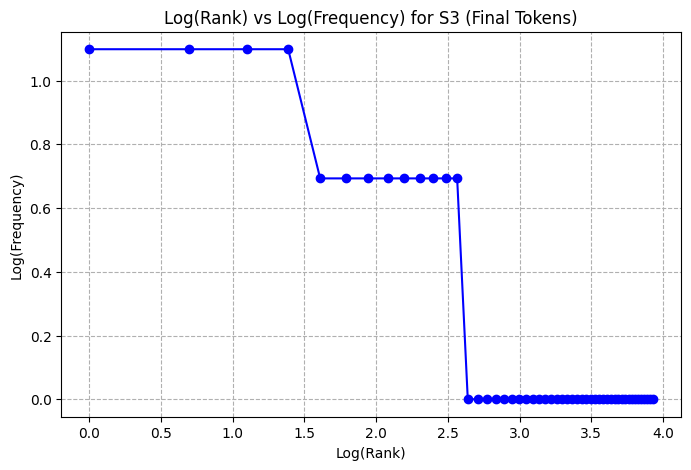

In [16]:
# Your code
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams
import pandas as pd

all_tokens = []
no_punct_tokens = []
final_tokens = []


for text in df['Ticket_Text']:
    analysis = process_ticket(text)
    all_tokens.extend(analysis['tokens'])
    no_punct_tokens.extend([t for t in analysis['tokens'] if not is_punct(t)])
    final_tokens.extend(analysis['final'])

porter = PorterStemmer()
stemmed_final_tokens = [porter.stem(t) for t in final_tokens]

def get_stats(tokens):
    tot = len(tokens)
    uniq = len(set(tokens))
    ttr = uniq / tot if tot > 0 else 0
    return tot, uniq, ttr

s1_tot, s1_uniq, s1_ttr = get_stats(all_tokens)
s2_tot, s2_uniq, s2_ttr = get_stats(no_punct_tokens)
s3_tot, s3_uniq, s3_ttr = get_stats(final_tokens)
s4_tot, s4_uniq, s4_ttr = get_stats(stemmed_final_tokens)

stats_df = pd.DataFrame({
    'Subset': ['S1 (All)', 'S2 (No Punct)', 'S3 (Final)', 'S4 (Stemmed Final)'],
    'Total Tokens': [s1_tot, s2_tot, s3_tot, s4_tot],
    'Unique Tokens (Vocab)': [s1_uniq, s2_uniq, s3_uniq, s4_uniq],
    'TTR': [s1_ttr, s2_ttr, s3_ttr, s4_ttr]
})
print("=== Corpus Statistics (S1 to S4) ===")
display(stats_df)

s1_counts = Counter(all_tokens)
s3_counts = Counter(final_tokens)

print("\n=== Top 10 Words in S1 ===")
for word, freq in s1_counts.most_common(10):
    print(f"  {word}: {freq}")

print("\n=== Top 10 Words in S3 ===")
for word, freq in s3_counts.most_common(10):
    print(f"  {word}: {freq}")

s1_bigrams = Counter(bigrams(all_tokens))
s3_bigrams = Counter(bigrams(final_tokens))

print("\n=== Top 5 Bigrams in S1 ===")
for bg, freq in s1_bigrams.most_common(5):
    print(f"  {' '.join(bg)}: {freq}")

print("\n=== Top 5 Bigrams in S3 ===")
for bg, freq in s3_bigrams.most_common(5):
    print(f"  {' '.join(bg)}: {freq}")

s3_sorted_freqs = sorted(s3_counts.values(), reverse=True)
ranks = np.arange(1, len(s3_sorted_freqs) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(s3_sorted_freqs), marker='o', linestyle='-', color='b')
plt.title("Log(Rank) vs Log(Frequency) for S3 (Final Tokens)")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True, which="both", ls="--")
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

1. **S1 (All Tokens) to S2 (No Punctuation) [TTR increases from 0.563 to 0.630]:**
   Removing highly repetitive punctuation tokens (like periods and exclamation marks) reduces the total token count (denominator) much faster than the unique token count (numerator), which increases the lexical density.

2. **S2 (No Punctuation) to S3 (Final Tokens) [TTR increases from 0.630 to 0.750]:**
   Filtering out stopwords (highly frequent, repetitive words like *the*, *is*, *i*) drastically reduces the total tokens from 119 to 68. Since we keep the highly diverse unique content words, removing these frequent grammatical words results in the highest TTR (highest vocabulary diversity).

3. **S3 (Final) to S4 (Stemmed Final) [TTR decreases from 0.750 to 0.735]:**
   Stemming collapses morphological variants of the same word (e.g., *keeps* and *keep*) into a single base stem. This decreases the number of unique tokens (vocabulary size) from 51 to 50 while keeping the total token count at 68, thereby slightly lowering the TTR.